# 06 · Experimentos: diseño y lectura de un A/B (Hillstrom)

**Sesión 6 · Experimentos** (ruta Paid Media, semana 5: prueba A/B con CUPED; catálogo: A/B con tamaño de muestra, A/B avanzado: CUPED, secuencial, bayesiano).

64.000 clientes sorteados en tres grupos: sin e-mail, e-mail de hombres y e-mail de mujeres; resultado a 2 semanas. Decisión 008: métrica principal **gasto**, guía **visita**, efecto mínimo +50%, lectura clásica y bayesiana. `python -m growth_lab.experimentos`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from growth_lab import experimentos as ex

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
s = ex.generar()
d = ex.cargar()
d.groupby("segment")[["visit", "conversion", "spend"]].agg(["mean", "count"]).round(4)

visit        conversion          spend       
                 mean  count       mean  count    mean  count
segment                                                      
Mens E-Mail    0.1828  21307     0.0125  21307  1.4226  21307
No E-Mail      0.1062  21306     0.0057  21306  0.6528  21306
Womens E-Mail  0.1514  21387     0.0088  21387  1.0772  21387

## 1. ¿El sorteo salió bien?

- **SRM** (*sample ratio mismatch*): si los grupos no tienen el tamaño esperado, algo falló en la asignación y el experimento no sirve.
- **Balance:** la diferencia estandarizada (SMD) de cada variable previa debería ser < 0,1.

In [2]:
b = s["exp_balance"]
print(f"SRM p-valor = {b.srm_p_valor.iloc[0]:.3f} (se busca > 0,01) · |SMD| máximo = {b.smd.abs().max():.3f}")
b.assign(smd_abs=b.smd.abs()).nlargest(6, "smd_abs")[["brazo", "variable", "media_tratado", "media_control", "smd"]].round(3)

SRM p-valor = 0.904 (se busca > 0,01) · |SMD| máximo = 0.014


,brazo,variable,media_tratado,media_control,smd
5,Mens E-Mail,zip_code_Rural,0.152,0.147,0.014
6,Mens E-Mail,zip_code_Surburban,0.446,0.452,-0.012
10,Mens E-Mail,channel_Web,0.445,0.440,0.011
13,Womens E-Mail,mens,0.549,0.553,-0.009
20,Womens E-Mail,channel_Phone,0.442,0.438,0.009
9,Mens E-Mail,channel_Phone,0.434,0.438,-0.008


## 2. Potencia: cuánta gente hacía falta

Con 21.300 por grupo, el efecto mínimo detectable del gasto es +48%: el diseño alcanza justo para el MDE de +50% (decisión 008).

,metrica,base_control,mde_relativo,n_por_grupo_disponible
4,spend,0.6528,0.4818,21306
9,visit,0.1062,0.0788,21306
14,conversion,0.0057,0.3577,21306


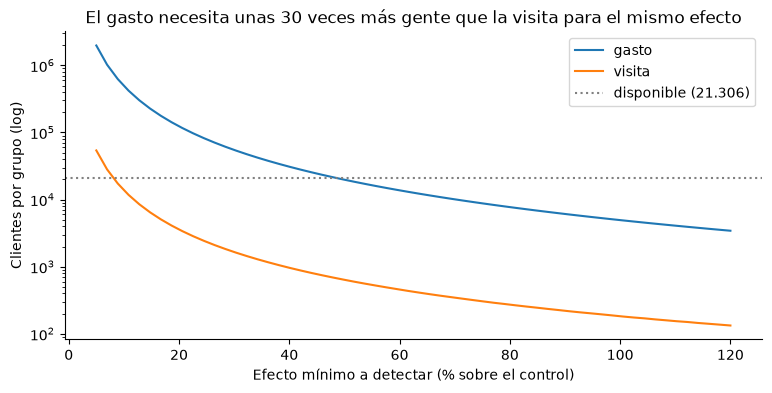

In [3]:
pot = s["exp_potencia"]
display(pot[pot.es_mde_alcanzable == True][["metrica", "base_control", "mde_relativo", "n_por_grupo_disponible"]].round(4))
lifts = np.linspace(0.05, 1.2, 60)
c = d[d.segment == ex.CONTROL]
fig, ax = plt.subplots()
ax.plot(lifts * 100, [ex.n_por_grupo_media(c.spend.std(), c.spend.mean() * l) for l in lifts], label="gasto")
ax.plot(lifts * 100, [ex.n_por_grupo_proporcion(c.visit.mean(), l) for l in lifts], label="visita")
ax.axhline(len(c), color="grey", ls=":", label="disponible (21.306)")
ax.set_yscale("log"); ax.set_xlabel("Efecto mínimo a detectar (% sobre el control)"); ax.set_ylabel("Clientes por grupo (log)")
ax.set_title("El gasto necesita unas 30 veces más gente que la visita para el mismo efecto"); ax.legend(); plt.show()

## 3. Efecto de cada e-mail (IC 95%; p ajustado por Holm)

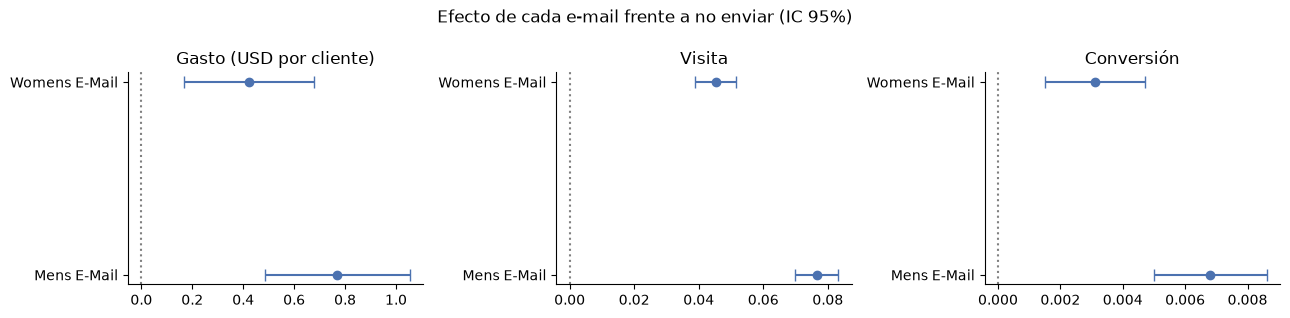

,metrica,brazo,control,tratado,dif,ic_inf,ic_sup,lift,p_valor,p_holm,ic_boot_inf,ic_boot_sup
0,spend,Mens E-Mail,0.6528,1.4226,0.7698,0.4851,1.0545,1.1793,0.0000,0.0000,0.4908,1.0539
1,spend,Womens E-Mail,0.6528,1.0772,0.4244,0.1690,0.6799,0.6502,0.0011,0.0011,0.1729,0.6736
2,visit,Mens E-Mail,0.1062,0.1828,0.0766,0.0700,0.0832,0.7214,0.0000,0.0000,NaN,NaN
3,visit,Womens E-Mail,0.1062,0.1514,0.0452,0.0389,0.0516,0.4261,0.0000,0.0000,NaN,NaN
4,conversion,Mens E-Mail,0.0057,0.0125,0.0068,0.0050,0.0086,1.1884,0.0000,0.0000,NaN,NaN
5,conversion,Womens E-Mail,0.0057,0.0088,0.0031,0.0015,0.0047,0.5433,0.0002,0.0002,NaN,NaN
6,spend,Mens vs Womens,1.0772,1.4226,0.3454,0.0326,0.6583,0.3207,0.0305,NaN,NaN,NaN
7,visit,Mens vs Womens,0.1514,0.1828,0.0314,0.0243,0.0384,0.2071,0.0000,NaN,NaN,NaN
8,conversion,Mens vs Womens,0.0088,0.0125,0.0037,0.0017,0.0056,0.4180,0.0002,NaN,NaN,NaN


In [4]:
ef = s["exp_efectos"]
vs = ef[ef.brazo.isin(ex.TRATAMIENTOS)]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for a, (m, titulo) in zip(axs, [("spend", "Gasto (USD por cliente)"), ("visit", "Visita"), ("conversion", "Conversión")]):
    g = vs[vs.metrica == m]
    a.errorbar(g.dif, range(len(g)), xerr=[g.dif - g.ic_inf, g.ic_sup - g.dif], fmt="o", capsize=4, color="#4C72B0")
    a.axvline(0, color="grey", ls=":"); a.set_yticks(range(len(g)), g.brazo); a.set_title(titulo)
fig.suptitle("Efecto de cada e-mail frente a no enviar (IC 95%)"); fig.tight_layout()
fig.savefig("../docs/img/exp_efectos.png", dpi=150); plt.show()
ef[["metrica", "brazo", "control", "tratado", "dif", "ic_inf", "ic_sup", "lift", "p_valor", "p_holm", "ic_boot_inf", "ic_boot_sup"]].round(4)

## 4. CUPED: ¿cuánto ruido quitan las variables previas?

CUPED resta la parte del resultado que ya se podía predecir antes del experimento. Solo ayuda si esa variable previa predice el resultado. Aquí `history` (gasto de los 12 meses previos) se correlaciona 0,02 con el gasto: casi no ayuda.

In [5]:
cu = s["exp_cuped"]
cu.pivot_table(index=["metrica", "brazo"], columns="metodo", values="reduccion_varianza").round(4)

metodo                    cuped_history  regresion_previas  sin_ajuste
metrica    brazo                                                      
conversion Mens E-Mail           0.0009             0.0021         0.0
           Womens E-Mail         0.0006             0.0016         0.0
spend      Mens E-Mail           0.0004             0.0012         0.0
           Womens E-Mail         0.0004             0.0007         0.0
visit      Mens E-Mail           0.0044             0.0283         0.0
           Womens E-Mail         0.0040             0.0255         0.0

## 5. Mirar antes de tiempo (*peeking*)

Simulación A/A: se parte el grupo de control en dos (sin efecto real) y se mira el resultado 20 veces mientras llegan los datos.

,miradas,reps,fp_mirando_siempre,fp_obrien_fleming,fp_una_sola_mirada
0,20,2000,0.228,0.047,0.048


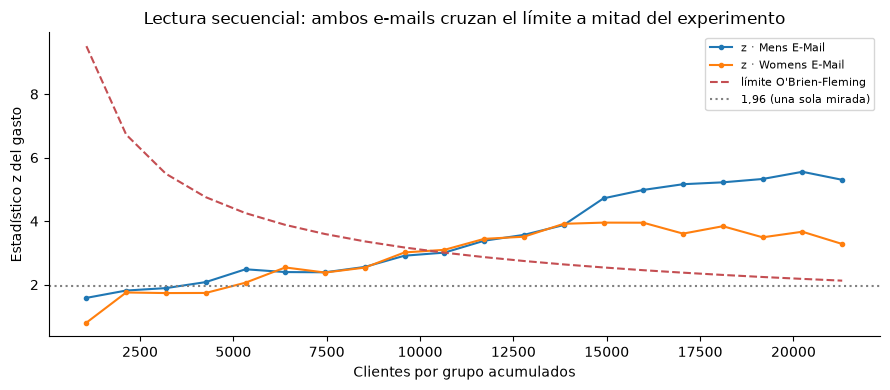

In [6]:
display(s["exp_peeking"].round(3))
sec = s["exp_secuencial"]
fig, ax = plt.subplots()
for brazo, g in sec.groupby("brazo"):
    ax.plot(g.n_por_grupo, g.z, marker="o", ms=3, label=f"z · {brazo}")
g0 = sec[sec.brazo == ex.TRATAMIENTOS[0]]
ax.plot(g0.n_por_grupo, g0.limite_obf, color="#C44E52", ls="--", label="límite O'Brien-Fleming")
ax.axhline(1.96, color="grey", ls=":", label="1,96 (una sola mirada)")
ax.set_xlabel("Clientes por grupo acumulados"); ax.set_ylabel("Estadístico z del gasto")
ax.set_title("Lectura secuencial: ambos e-mails cruzan el límite a mitad del experimento"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("../docs/img/exp_secuencial.png", dpi=150); plt.show()

## 6. Lectura bayesiana

Probabilidad de que el e-mail sea mejor que no enviar, mejora esperada con intervalo creíble del 90% y pérdida esperada si se elige el e-mail y en realidad era peor.

In [7]:
s["exp_bayes"].round(4)

,metrica,brazo,p_mejor,lift_esperado,lift_p05,lift_p95,perdida_esperada
0,visit,Mens E-Mail,1.0000,0.7216,0.6529,0.7922,0.0
1,conversion,Mens E-Mail,1.0000,1.1957,0.8276,1.6136,0.0
2,spend,Mens E-Mail,1.0000,1.2099,0.7080,1.7989,0.0
3,visit,Womens E-Mail,1.0000,0.4263,0.3671,0.4873,0.0
4,conversion,Womens E-Mail,0.9999,0.5507,0.2752,0.8652,0.0
5,spend,Womens E-Mail,0.9998,0.6725,0.2891,1.1175,0.0


## 7. ¿Es rentable? (decisión 009: margen 30% como parámetro)

In [8]:
s["exp_economia"].round(3)

,brazo,gasto_incremental_por_1000,ic_inf_por_1000,ic_sup_por_1000,costo_max_por_correo,costo_max_ic_inf,costo_max_margen_20,costo_max_margen_40,margen_supuesto
0,Mens E-Mail,769.827,485.149,1054.505,0.231,0.146,0.154,0.308,0.3
1,Womens E-Mail,424.412,168.965,679.860,0.127,0.051,0.085,0.170,0.3


## Mis conclusiones (Neider)

1. **El experimento es confiable:** los grupos tienen el tamaño esperado (SRM p = 0,90) y están balanceados en todo lo previo (|SMD| ≤ 0,014).
2. **Los dos correos funcionan:** el de hombres sube el gasto +0,77 USD por cliente (+118%) y el de mujeres +0,42 (+65%), ambos significativos después de Holm. El de hombres le gana al de mujeres (+0,35, p = 0,03), así que hoy lo mandaría a todos.
3. **Es rentable con cualquier margen razonable:** con 30%, cada correo de hombres deja hasta 0,23 USD de margen incremental, y un correo cuesta centavos.
4. **CUPED no es magia:** solo quita ruido si lo de antes predice lo de después. Aquí el gasto previo casi no se relaciona con el de estas dos semanas, así que la reducción fue menor al 0,1%.
5. **No hay que mirar todos los días sin corregir:** con 20 miradas, los falsos positivos suben de 5% a 23%. Con O'Brien-Fleming se puede mirar seguido sin hacer trampa, y aquí se habría podido parar con la mitad de la muestra.
6. **Lo que sigue:** el promedio esconde que a algunos clientes el correo no les cambia nada. La sesión 7 (uplift) dirá a quién mandarle cuál.